In [ ]:
%pip install category_encoders
%pip install scikit-learn
%pip install pandas
%pip install numpy
%pip install matplotlib

: 

In [2]:
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import category_encoders as ce
import matplotlib.pyplot as plt

In [3]:
data = pd.read_csv("mental_health_cleaned.csv")

In [4]:
feature_cols = [
    "Code",
    "Schizophrenia disorders (share of population)",
    "Depressive disorders (share of population)",
    "Anxiety disorders (share of population)",
    "Bipolar disorders (share of population)",
]

X = data[feature_cols]
y = data["Year"]

# 2. Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [5]:
categorical_cols = ["Code"]
numerical_cols = [c for c in feature_cols if c not in categorical_cols]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore", sparse_output=True),
            categorical_cols,
        ),
        ("num", StandardScaler(), numerical_cols),
    ]
)

# 4. Evaluate Models using Pipelines
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest Regressor": RandomForestRegressor(
        n_estimators=100, random_state=42
    ),
}

for name, model in models.items():
    pipeline = Pipeline(
        steps=[("preprocessor", preprocessor), ("regressor", model)]
    )

    pipeline.fit(X_train, y_train)
    preds = pipeline.predict(X_test)

    mse = mean_squared_error(y_test, preds)
    mae = mean_absolute_error(y_test, preds)
    r2 = r2_score(y_test, preds)

    print(f"=== {name} ===")
    print(f"Mean Absolute Error (MAE): {mae:.2f} years")
    print(f"Mean Squared Error (MSE):  {mse:.2f}")
    print(f"R^2 Score:                 {r2:.4f}\n")

=== Linear Regression ===
Mean Absolute Error (MAE): 7.08 years
Mean Squared Error (MSE):  70.49
R^2 Score:                 0.0239

=== Random Forest Regressor ===
Mean Absolute Error (MAE): 1.74 years
Mean Squared Error (MSE):  6.99
R^2 Score:                 0.9033



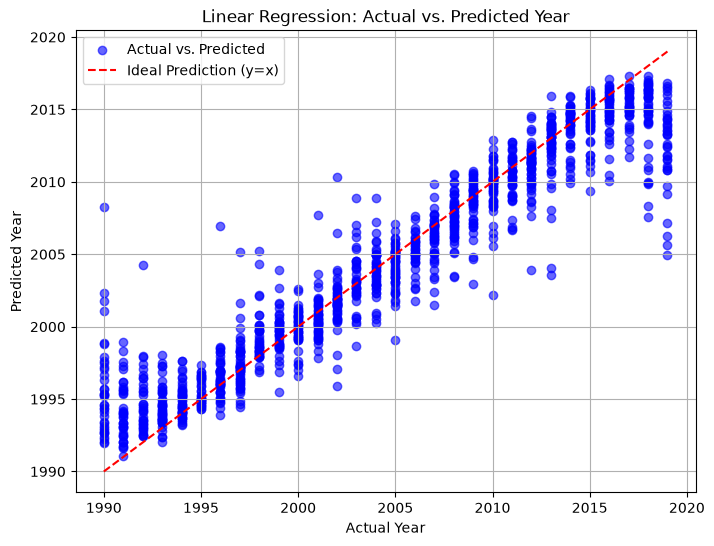

In [6]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, preds, alpha=0.6, color='blue', label='Actual vs. Predicted')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', label='Ideal Prediction (y=x)') # Add a 45-degree line for reference
plt.xlabel('Actual Year')
plt.ylabel('Predicted Year')
plt.title('Linear Regression: Actual vs. Predicted Year')
plt.legend()
plt.grid(True)
plt.show()